In [0]:

# Install required packages
%pip install transformers torch datasets evaluate
%pip install accelerate xformers   # For GPU acceleration
%pip install seaborn


Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 88.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 427.2/427.2 MB 75.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 444.6/444.6 MB 73.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.1/221.1 MB 88.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.0/206.0 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.7/184.7 MB 74.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.8/542.8 MB 67.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 82.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 MB 89.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 62.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 84.8 MB/s eta 0:00:00
   ━━━━━━

In [0]:
import pandas as pd
from transformers import pipeline, AutoModelForSequenceClassification, AutoTokenizer
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Define a modern sentiment analysis pipeline
def create_sentiment_analyzer(model_name="distilbert-base-uncased-finetuned-sst-2-english"):
    return pipeline(
        "sentiment-analysis",
        model=model_name,
        tokenizer=model_name,
        device="cuda" if torch.cuda.is_available() else "cpu"
    )

# Load and prepare sample dataset
reviews = [
    "The new language model's performance is exceptional!",
    "The system response time needs significant improvement.",
    "A balanced product with both strengths and limitations.",
    "Customer support was incredibly responsive and helpful.",
    "The documentation is outdated and hard to follow."
]

df = pd.DataFrame({'review': reviews})



/local_disk0/.ephemeral_nfs/envs/pythonEnv-4cea8f1b-4a22-43f0-9df5-9a1e2b1d0790/lib/python3.12/site-packages/torch/_vmap_internals.py:9: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  from torch.utils._pytree import _broadcast_to_and_flatten, tree_flatten, tree_unflatten


In [0]:
# Perform analysis
def analyze_sentiments(df, analyzer):
    results = []
    for review in df['review']:
        analysis = analyzer(review)[0]
        results.append({
            'text': review,
            'sentiment': analysis['label'],
            'confidence': analysis['score']
        })
    return pd.DataFrame(results)


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]


Analysis Results:
                                                text sentiment  confidence
0  The new language model's performance is except...  POSITIVE    0.999866
1  The system response time needs significant imp...  NEGATIVE    0.998769
2  A balanced product with both strengths and lim...  POSITIVE    0.999856
3  Customer support was incredibly responsive and...  POSITIVE    0.999683
4  The documentation is outdated and hard to follow.  NEGATIVE    0.999773


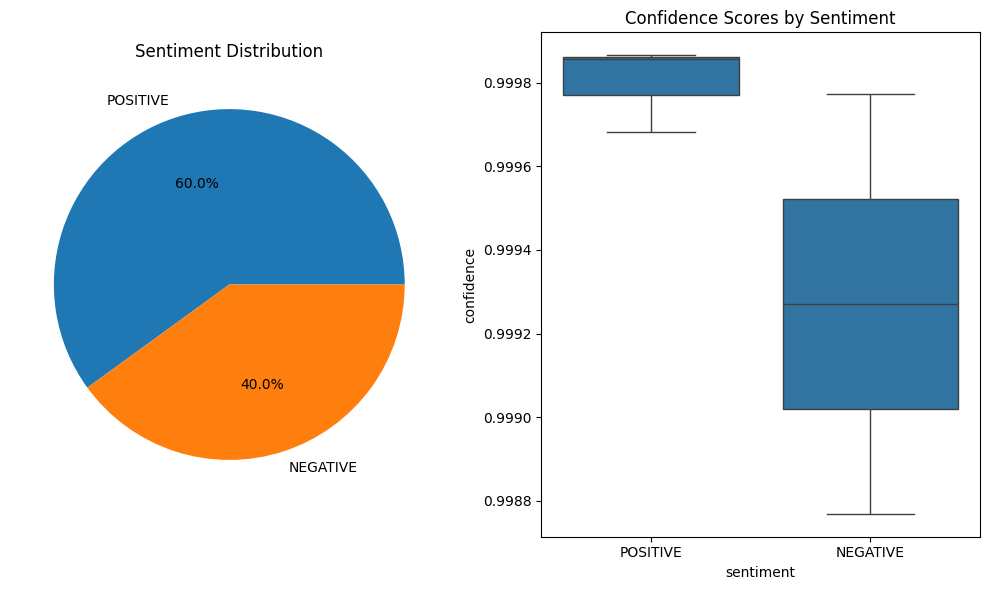

In [0]:
# Create visualizations
def plot_sentiment_distribution(results_df):
    plt.figure(figsize=(10, 6))
    
    # Sentiment distribution
    plt.subplot(1, 2, 1)
    sentiment_counts = results_df['sentiment'].value_counts()
    plt.pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%')
    plt.title('Sentiment Distribution')
    
    # Confidence scores
    plt.subplot(1, 2, 2)
    sns.boxplot(x='sentiment', y='confidence', data=results_df)
    plt.title('Confidence Scores by Sentiment')
    
    plt.tight_layout()
    plt.show()

# Main execution
sentiment_analyzer = create_sentiment_analyzer()
results_df = analyze_sentiments(df, sentiment_analyzer)

# Display results
print("\nAnalysis Results:")
print(results_df)

# Create visualizations
plot_sentiment_distribution(results_df)
